# Mini Project 3

## Generated Seed: 199593370

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate, stats
from mp3lib import (sample_mean_cov, is_valid_covariance, gaussian_pdf,
                    whitening_matrix, lmmse_weights)

SEED = 199593370   # drawn once, do not change
rng = np.random.default_rng(SEED)

# One generator per step, spawned once here. No default_rng calls below this cell.
rng1 = rng.spawn(1)[0]
rng2 = rng.spawn(1)[0]
rng3 = rng.spawn(1)[0]
rng4 = rng.spawn(1)[0]
rng5 = rng.spawn(1)[0]
rng6 = rng.spawn(1)[0]
rng7 = rng.spawn(1)[0]
rng8 = rng.spawn(1)[0]

t_start = time.time()   # used to report total runtime at the end

---
# Step 1: Two variables at once

Joint density: $f_{XY}(x,y) = x + y$ for $0 \le x \le 1,\ 0 \le y \le 1$

### Verify by hand
The density is non-negative on the unit square, and it integrates to one:
$$
\int_0^1\!\!\int_0^1 (x+y)\,dy\,dx
= \int_0^1 \left[xy + \tfrac{y^2}{2}\right]_0^1 dx
= \int_0^1 \left(x + \tfrac12\right) dx
= \tfrac12 + \tfrac12 = 1 
$$

In [2]:
f_xy = lambda y, x: x + y   # dblquad expects f(y, x)

# 2D quadrature over the unit square
total, total_err = integrate.dblquad(f_xy, 0, 1, 0, 1)
print(f"Integral of f_XY over unit square = {total:.12f}  (|1 - integral| = {abs(1-total):.2e})")

Integral of f_XY over unit square = 1.000000000000  (|1 - integral| = 0.00e+00)


### Marginals by hand
$$
f_X(x) = \int_0^1 (x+y)\,dy = x + \tfrac12, \qquad
f_Y(y) = \int_0^1 (x+y)\,dx = y + \tfrac12 
$$
By symmetry the two marginals have the same form. Below we integrate the joint density over the other variable on a grid (trapezoid rule) and compare.

In [3]:
# Evaluate the joint density on a grid
g = np.linspace(0, 1, 1001)
XX, YY = np.meshgrid(g, g, indexing="ij")   # XX[i, j] = g[i], YY[i, j] = g[j]
F = XX + YY

# Numerical marginals: integrate out the other variable
fX_num = np.trapezoid(F, g, axis=1)   # integrate over y
fY_num = np.trapezoid(F, g, axis=0)   # integrate over x
f_marg = g + 0.5                      # analytic marginal (same for X and Y)

print(f"max |f_X numeric - analytic| = {np.max(np.abs(fX_num - f_marg)):.2e}")
print(f"max |f_Y numeric - analytic| = {np.max(np.abs(fY_num - f_marg)):.2e}")
print(f"f_X(0.3) analytic = {0.3 + 0.5:.4f}, numeric = {np.interp(0.3, g, fX_num):.6f}")

max |f_X numeric - analytic| = 2.22e-16
max |f_Y numeric - analytic| = 8.88e-16
f_X(0.3) analytic = 0.8000, numeric = 0.800000


### Conditional density of $Y$ given $X=x$
$$
f_{Y|X}(y \mid x) = \frac{f_{XY}(x,y)}{f_X(x)} = \frac{x+y}{x+\tfrac12}, \qquad 0 \le y \le 1 
$$
At $x = 0.3$: $f_{Y|X}(y \mid 0.3) = \dfrac{0.3 + y}{0.8}$, a straight line from $0.375$ to $1.625$

### $x=0.3$ conditional density plot in Figure 1(c) 

In [4]:
x0 = 0.3
f_cond = lambda y: (x0 + y) / (x0 + 0.5)

cond_int, _ = integrate.quad(f_cond, 0, 1)
print(f"Integral of f(y | x=0.3) over [0,1] = {cond_int:.12f}  (|1 - integral| = {abs(1-cond_int):.2e})")

Integral of f(y | x=0.3) over [0,1] = 1.000000000000  (|1 - integral| = 1.11e-16)


### Moments
$$
E[X] = \int_0^1 x\left(x+\tfrac12\right)dx = \tfrac13 + \tfrac14 = \tfrac{7}{12}, \qquad E[Y] = \tfrac{7}{12}\ 
$$
$$
E[X^2] = \int_0^1 x^2\left(x+\tfrac12\right)dx = \tfrac14 + \tfrac16 = \tfrac{5}{12}, \qquad
\mathrm{Var}(X) = \tfrac{5}{12} - \left(\tfrac{7}{12}\right)^2 = \tfrac{60-49}{144} = \tfrac{11}{144}
$$
$$
E[XY] = \int_0^1\!\!\int_0^1 xy(x+y)\,dy\,dx = \int_0^1\!\!\int_0^1 (x^2y + xy^2)\,dy\,dx = \tfrac16 + \tfrac16 = \tfrac13
$$
$$
\mathrm{Cov}(X,Y) = \tfrac13 - \tfrac{49}{144} = \tfrac{48-49}{144} = -\tfrac{1}{144}, \qquad
\rho = \frac{-1/144}{11/144} = -\tfrac{1}{11}
$$

In [5]:
# Analytic values from the derivation above
EX_a, EXY_a, VarX_a = 7/12, 1/3, 11/144
Cov_a = EXY_a - EX_a**2
rho_a = Cov_a / VarX_a

# 2D quadrature
q = lambda g: integrate.dblquad(lambda y, x: g(x, y) * (x + y), 0, 1, 0, 1)[0]
EX_q  = q(lambda x, y: x)
EY_q  = q(lambda x, y: y)
EXY_q = q(lambda x, y: x * y)
EX2_q = q(lambda x, y: x**2)
VarX_q = EX2_q - EX_q**2
Cov_q  = EXY_q - EX_q * EY_q

rho_q  = Cov_q / VarX_q   
# Var(Y) = Var(X) by symmetry

print(f"{'quantity':<10}{'analytic':>14}{'quadrature':>14}{'|diff|':>12}")
for name, a, n in [("E[X]", EX_a, EX_q), ("E[Y]", EX_a, EY_q), ("E[XY]", EXY_a, EXY_q),
                   ("Var(X)", VarX_a, VarX_q), ("Cov(X,Y)", Cov_a, Cov_q), ("rho", rho_a, rho_q)]:
    print(f"{name:<10}{a:>14.7f}{n:>14.7f}{abs(a-n):>12.1e}")

quantity        analytic    quadrature      |diff|
E[X]           0.5833333     0.5833333     1.1e-16
E[Y]           0.5833333     0.5833333     1.1e-16
E[XY]          0.3333333     0.3333333     1.1e-16
Var(X)         0.0763889     0.0763889     5.6e-17
Cov(X,Y)      -0.0069444    -0.0069444     2.8e-16
rho           -0.0909091    -0.0909091     3.7e-15


### Rejection sampling

**Bounding constant.** Propose $(x,y)$ uniformly on the unit square, so the proposal density is $g(x,y)=1$. We need $f \le M g$ everywhere, and $f$ is largest at $(1,1)$ where $f = 2$, so the tightest choice is $M = 2$. Accept a proposal when $u \le f(x,y)/M = (x+y)/2$ with $u \sim U(0,1)$. The expected acceptance rate is $1/M = 0.5$.

Standard errors: for a sample average of a quantity $Z$, $\mathrm{SE} = s_Z/\sqrt N$. For the variance and covariance we use the sample std of $(X-\bar X)^2$ and $(X-\bar X)(Y-\bar Y)$, and for $\rho$ the large-sample approximation $(1-\rho^2)/\sqrt N$.

In [6]:
def sample_joint(n, rng, M=2.0):
    # Rejection sampler for f(x,y) = x + y on the unit square, vectorized in batches.
    accepted, n_prop = [], 0
    n_have = 0
    while n_have < n:
        m = int(1.1 * M * (n - n_have)) + 1000          # batch size: enough for what's left
        xy = rng.random((m, 2))                         # uniform proposals
        u = rng.random(m)
        keep = u <= xy.sum(axis=1) / M                  # accept with prob f/M
        accepted.append(xy[keep]); n_prop += m; n_have += keep.sum()
    samples = np.vstack(accepted)
    return samples[:n], samples.shape[0] / n_prop       # (samples, acceptance rate)

N1 = 10**6
S1, acc_rate = sample_joint(N1, rng1)
xs, ys = S1[:, 0], S1[:, 1]
print(f"Acceptance rate = {acc_rate:.4f}  (expected 1/M = 0.5)\n")

# Sample statistics and standard errors
xc, yc = xs - xs.mean(), ys - ys.mean()
rho_s = np.corrcoef(xs, ys)[0, 1]
rows = [
    ("E[X]",     EX_a,   xs.mean(),            xs.std() / np.sqrt(N1)),
    ("E[Y]",     EX_a,   ys.mean(),            ys.std() / np.sqrt(N1)),
    ("E[XY]",    EXY_a,  (xs*ys).mean(),       (xs*ys).std() / np.sqrt(N1)),
    ("Var(X)",   VarX_a, (xc**2).mean(),       (xc**2).std() / np.sqrt(N1)),
    ("Cov(X,Y)", Cov_a,  (xc*yc).mean(),       (xc*yc).std() / np.sqrt(N1)),
    ("rho",      rho_a,  rho_s,                (1 - rho_s**2) / np.sqrt(N1)),
]
print(f"{'quantity':<10}{'analytic':>12}{'sample':>12}{'SE':>11}{'diff/SE':>9}")
for name, a, s, se in rows:
    print(f"{name:<10}{a:>12.6f}{s:>12.6f}{se:>11.2e}{(s-a)/se:>9.2f}")

Acceptance rate = 0.5006  (expected 1/M = 0.5)

quantity      analytic      sample         SE  diff/SE
E[X]          0.583333    0.583759   2.76e-04     1.54
E[Y]          0.583333    0.583175   2.77e-04    -0.57
E[XY]         0.333333    0.333479   2.36e-04     0.62
Var(X)        0.076389    0.076418   7.64e-05     0.38
Cov(X,Y)     -0.006944   -0.006954   7.49e-05    -0.13
rho          -0.090909   -0.090963   9.92e-04    -0.05


### Figure 1

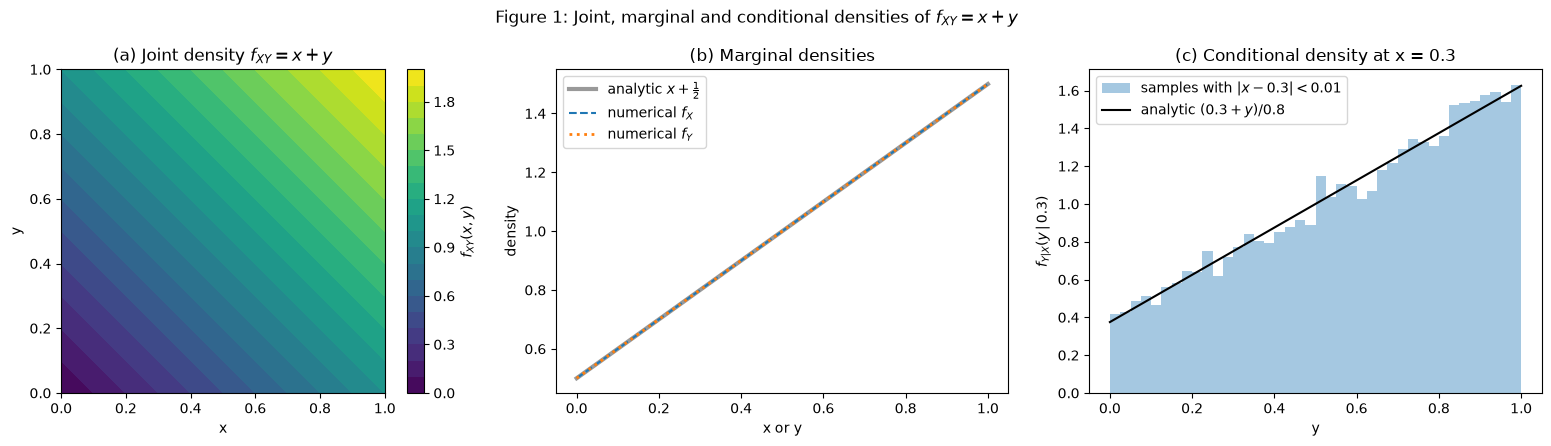

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) joint density
cf = ax[0].contourf(XX, YY, F, levels=20, cmap="viridis")
fig.colorbar(cf, ax=ax[0], label=r"$f_{XY}(x,y)$")
ax[0].set(xlabel="x", ylabel="y", title="(a) Joint density $f_{XY}=x+y$")
ax[0].set_aspect("equal")

# (b) marginals: analytic vs numerical
ax[1].plot(g, f_marg, "k-", lw=3, alpha=0.4, label=r"analytic $x+\frac{1}{2}$")
ax[1].plot(g, fX_num, "C0--", label=r"numerical $f_X$")
ax[1].plot(g, fY_num, "C1:", lw=2, label=r"numerical $f_Y$")
ax[1].set(xlabel="x or y", ylabel="density", title="(b) Marginal densities")
ax[1].legend()

# (c) conditional at x = 0.3, with a histogram of samples in a thin slice near x = 0.3
sl = np.abs(xs - x0) < 0.01
ax[2].hist(ys[sl], bins=40, density=True, alpha=0.4, label=r"samples with $|x-0.3|<0.01$")
ax[2].plot(g, f_cond(g), "k-", label=r"analytic $(0.3+y)/0.8$")
ax[2].set(xlabel="y", ylabel=r"$f_{Y|X}(y\,|\,0.3)$", title="(c) Conditional density at x = 0.3")
ax[2].legend()

fig.suptitle("Figure 1: Joint, marginal and conditional densities of $f_{XY}=x+y$")
plt.tight_layout(); plt.show()

**Interpretation of Figure 1.** (a) The density rises linearly from 0 at the origin to 2 at the corner $(1,1)$, with straight contour lines along $x+y=\text{const}$. (b) The numerical marginals (dashed/dotted) sit on top of the analytic line $x + \tfrac12$; the printed max error is at the level of the trapezoid rule's rounding, so the derivation is confirmed. (c) Given $x=0.3$, larger $y$ values are more likely, and the conditional is a line from $0.375$ to $1.625$; the histogram of rejection samples in a thin slice around $x=0.3$ follows it.

### Why the correlation is negative
The conditional mean $E[Y\mid X=x] = \dfrac{x/2 + 1/3}{x + 1/2}$ *decreases* in $x$: when $x$ is small, the density $x+y$ is driven almost entirely by $y$, so the mass is pushed toward large $y$, while when $x$ is large the $x$ term already makes the density big everywhere and $y$ becomes nearly uniform. So a small $X$ goes with a relatively large $Y$ and vice versa, which gives a small negative correlation even though the density itself is largest where both are large.

---
# Step 2: Uncorrelated does not mean independent

### Covariance by hand
Let $X \sim U(-1,1)$, so $f_X(x) = \tfrac12$ on $[-1,1]$, and let $Y = X^2$
$$
E[X] = 0, \qquad E[X^3] = \int_{-1}^{1} \tfrac12 x^3\,dx = \left. \frac{1}{8}  x^4 \right\rvert_{-1}^{1} = 0 \quad 
$$
$$
\mathrm{Cov}(X,Y) = E[XY] - E[X]E[Y] = E[X^3] - 0 \cdot E[X^2] = 0 
$$
$E[Y] = E[X^2] = \tfrac13 = \mathrm{Var}(X)$, $E[Y^2] = E[X^4] = \tfrac15$, so $\mathrm{Var}(Y) = \tfrac15 - \tfrac19 = \tfrac{4}{45}$.

In [8]:
N2 = 10**7
x2 = rng2.uniform(-1, 1, N2)
y2 = x2**2   # Y is a deterministic function of X

# Sample correlation and its standard error.
# SE at rho = 0 (delta method): std(xc*yc) / (sx * sy * sqrt(N))
xc2, yc2 = x2 - x2.mean(), y2 - y2.mean()
r2 = np.corrcoef(x2, y2)[0, 1]
se_r2 = (xc2 * yc2).std() / (x2.std() * y2.std() * np.sqrt(N2))

print(f"Sample correlation r = {r2:.2e},  SE = {se_r2:.2e},  r/SE = {r2/se_r2:.2f}")
print(f"(1/sqrt(N) = {1/np.sqrt(N2):.2e})")
print(f"E[Y]:   sample {y2.mean():.6f}  vs 1/3  = {1/3:.6f}  (SE {y2.std()/np.sqrt(N2):.1e})")
print(f"Var(X): sample {x2.var():.6f}  vs 1/3  = {1/3:.6f}  (SE {(xc2**2).std()/np.sqrt(N2):.1e})")
print(f"Var(Y): sample {y2.var():.6f}  vs 4/45 = {4/45:.6f}  (SE {(yc2**2).std()/np.sqrt(N2):.1e})")

Sample correlation r = 5.42e-05,  SE = 3.96e-04,  r/SE = 0.14
(1/sqrt(N) = 3.16e-04)
E[Y]:   sample 0.333460  vs 1/3  = 0.333333  (SE 9.4e-05)


Var(X): sample 0.333460  vs 1/3  = 0.333333  (SE 9.4e-05)


Var(Y): sample 0.088908  vs 4/45 = 0.088889  (SE 3.0e-05)


### Dependence: conditional variance in narrow bins
If $Y$ is a deterministic function of $X$, then $\mathrm{Var}(Y \mid X = x) = 0$. With bins of finite width $w$ we instead see the spread of $x^2$ across one bin, roughly $(2x)^2 w^2/12$, which should go to zero as the bins shrink.

In [9]:
def binned_cond_var(x, y, edges):
    # Var(Y | X in bin) for every bin, vectorized with bincount
    idx = np.clip(np.digitize(x, edges) - 1, 0, len(edges) - 2)
    n = np.bincount(idx, minlength=len(edges) - 1)
    s1 = np.bincount(idx, weights=y, minlength=len(edges) - 1)
    s2 = np.bincount(idx, weights=y**2, minlength=len(edges) - 1)
    m = s1 / n
    return s2 / n - m**2

# The conditional variance shrinks like (bin width)^2 -> it is zero in the limit
for nb in [20, 200, 2000]:
    cv = binned_cond_var(x2, y2, np.linspace(-1, 1, nb + 1))
    print(f"{nb:5d} bins: max Var(Y|X in bin) = {cv.max():.2e}   (unconditional Var(Y) = {4/45:.4f})")

nb = 200
edges2 = np.linspace(-1, 1, nb + 1)
centers2 = 0.5 * (edges2[:-1] + edges2[1:])
cv200 = binned_cond_var(x2, y2, edges2)

   20 bins: max Var(Y|X in bin) = 3.01e-03   (unconditional Var(Y) = 0.0889)


  200 bins: max Var(Y|X in bin) = 3.30e-05   (unconditional Var(Y) = 0.0889)


 2000 bins: max Var(Y|X in bin) = 3.39e-07   (unconditional Var(Y) = 0.0889)


### Figure 2

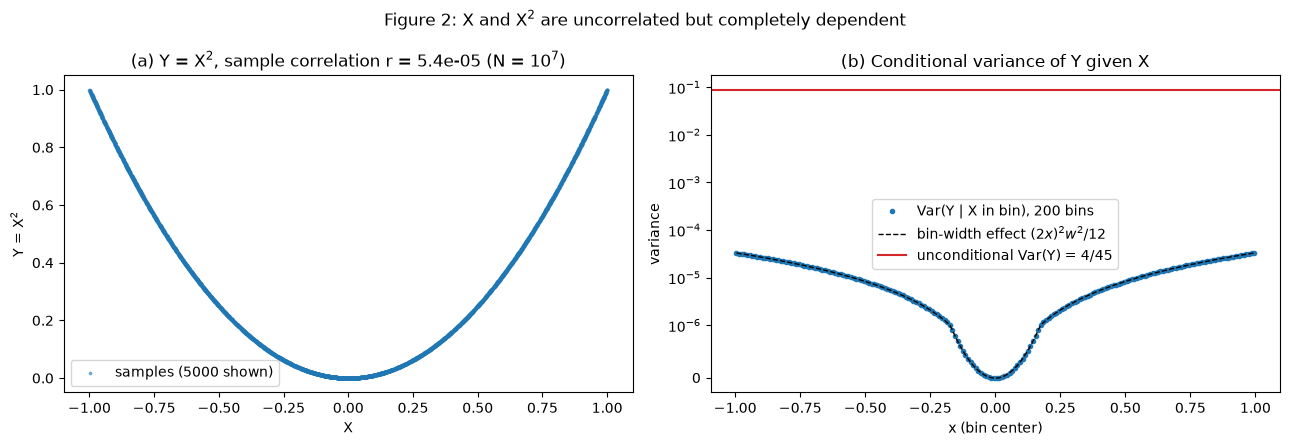

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) scatter of a subsample (plotting 10^7 points is slow and adds nothing)
sub = slice(0, 5000)
ax[0].scatter(x2[sub], y2[sub], s=3, alpha=0.5, label="samples (5000 shown)")
ax[0].set(xlabel="X", ylabel=r"Y = X$^2$",
          title=f"(a) Y = X$^2$, sample correlation r = {r2:.1e} (N = 10$^7$)")
ax[0].legend()

# (b) binned conditional variance vs the unconditional variance
w = edges2[1] - edges2[0]
ax[1].plot(centers2, cv200, "C0.", label=f"Var(Y | X in bin), {nb} bins")
ax[1].plot(centers2, (2 * centers2)**2 * w**2 / 12, "k--", lw=1, label=r"bin-width effect $(2x)^2w^2/12$")
ax[1].axhline(4/45, color="C3", label="unconditional Var(Y) = 4/45")
ax[1].set(xlabel="x (bin center)", ylabel="variance", title="(b) Conditional variance of Y given X")
ax[1].set_yscale("symlog", linthresh=1e-6)
ax[1].legend()

fig.suptitle("Figure 2: X and X$^2$ are uncorrelated but completely dependent")
plt.tight_layout(); plt.show()

**Interpretation of Figure 2.** (a) The points lie exactly on a parabola, so knowing $X$ tells you $Y$ with no uncertainty, yet the sample correlation in the title is within a couple of standard errors of zero. (b) Inside each narrow bin the variance of $Y$ is several orders of magnitude below the unconditional variance $4/45$, and what is left matches the pure bin-width effect (dashed line). The printed table shows it falling by about 100× every time the bins get 10× narrower, so in the limit $\mathrm{Var}(Y\mid X=x)=0$ everywhere.

### What correlation measures
The correlation coefficient measures only the strength of the **linear** relationship (how well a straight line fits $Y$ against $X$); for $Y = X^2$ on a symmetric interval the best-fitting line is flat, because the left half of the parabola cancels the right half, so $\rho = 0$ even though the dependence is perfect.

### The converse: a jointly Gaussian pair with $\rho = 0$
To test independence we split each axis into 10 equal-probability bins and compare the observed count in each of the 100 cells with what independence predicts (product of the marginals). A $\chi^2$ test of independence turns this into a single p-value. We run the same test on $(X, X^2)$ for contrast.

In [11]:
def independence_check(a, b, k=10):
    # Equal-probability bins on each axis (from the sample quantiles)
    ea = np.quantile(a, np.linspace(0, 1, k + 1)[1:-1])
    eb = np.quantile(b, np.linspace(0, 1, k + 1)[1:-1])
    ia, ib = np.searchsorted(ea, a), np.searchsorted(eb, b)
    table = np.bincount(ia * k + ib, minlength=k * k).reshape(k, k)   # joint counts

    joint = table / table.sum()                                      # empirical joint
    prod = np.outer(joint.sum(1), joint.sum(0))                      # product of marginals
    rel_dev = np.abs(joint - prod) / prod
    chi2, p, dof, _ = stats.chi2_contingency(table)
    return rel_dev.max(), chi2, dof, p

N2g = 10**6
G = rng2.multivariate_normal([0, 0], [[1, 0], [0, 1]], size=N2g)   # rho = 0 Gaussian pair

# Expected relative noise in one cell with p = 1/100: sqrt((1-p)/(N p))
noise = np.sqrt((1 - 0.01) / (N2g * 0.01))
for label, a, b in [("Gaussian, rho = 0", G[:, 0], G[:, 1]),
                    ("(X, X^2)", x2[:N2g], y2[:N2g])]:
    dev, chi2, dof, p = independence_check(a, b)
    print(f"{label:<18}: max |joint - product|/product = {dev:.4f}, "
          f"chi2 = {chi2:.1f} on {dof} dof, p = {p:.3g}")
print(f"Expected relative cell noise for N = 10^6: about {noise:.4f} (so ~3x that is a normal maximum over 100 cells)")
print(f"Sample correlation of the Gaussian pair: {np.corrcoef(G.T)[0,1]:.2e} (SE ~ {1/np.sqrt(N2g):.1e})")

Gaussian, rho = 0 : max |joint - product|/product = 0.0281, chi2 = 73.9 on 81 dof, p = 0.699
(X, X^2)          : max |joint - product|/product = 4.0666, chi2 = 3980082.8 on 81 dof, p = 0
Expected relative cell noise for N = 10^6: about 0.0099 (so ~3x that is a normal maximum over 100 cells)


Sample correlation of the Gaussian pair: 7.91e-04 (SE ~ 1.0e-03)


**Interpretation.** For the Gaussian pair the joint cell probabilities match the product of the marginals to within the sampling noise, and the $\chi^2$ statistic is about the size of its degrees of freedom with an unremarkable p-value, so there is no evidence of dependence. For $(X, X^2)$ the same test gives cell probabilities that are off by hundreds of times the noise level (some cells are empty, since $Y$ is pinned to $X^2$) and a p-value of essentially zero, even though its correlation is also zero.

### Why the Gaussian is special
For a jointly Gaussian vector the density depends on the data only through the mean and covariance, so if the off-diagonal covariance is zero, $\Sigma$ is diagonal, the quadratic form in the exponent splits into a sum, and the joint density factors into the product of the marginals, which is exactly independence. For other distributions the covariance captures only linear (second-order) structure, so nonlinear dependence like $Y = X^2$ is invisible to it. In engineering we routinely conclude "uncorrelated, therefore independent" (e.g. whitened noise samples, decorrelated channels), and that step is only valid if the Gaussian assumption actually holds, so the assumption is doing real work.

---
# Step 3: The covariance matrix and how well you can estimate it

$$
\Sigma = \begin{bmatrix} 4 & 2 & 1 & 0 \\ 2 & 5 & 2 & 1 \\ 1 & 2 & 3 & 1 \\ 0 & 1 & 1 & 2 \end{bmatrix}
$$

### Is $\Sigma$ a valid covariance matrix?
A covariance matrix must be symmetric and positive semidefinite (all eigenvalues $\ge 0$). We check with `is_valid_covariance` from `mp3lib.py`, which uses `eigvalsh` with a small tolerance for rounding.

In [12]:
Sigma3 = np.array([[4, 2, 1, 0],
                   [2, 5, 2, 1],
                   [1, 2, 3, 1],
                   [0, 1, 1, 2]], dtype=float)

eig3 = np.linalg.eigvalsh(Sigma3)   # eigvalsh: real eigenvalues for symmetric matrices
print(f"Symmetric: {np.array_equal(Sigma3, Sigma3.T)}")
print(f"Eigenvalues: {np.round(eig3, 4)}  (all positive: {np.all(eig3 > 0)})")
print(f"Determinant: {np.linalg.det(Sigma3):.6f}\n")

# Test cases for is_valid_covariance
A_nonsym = np.array([[2.0, 1.0], [0.0, 2.0]])          # not symmetric
A_negeig = np.array([[1.0, 2.0], [2.0, 1.0]])          # symmetric, eigenvalues -1 and 3
A_round  = np.array([[1.0, 1.0], [1.0, 1.0]]) - 1e-14 * np.eye(2)  # PSD up to rounding (eig ~ -1e-14)

tests = [("Sigma (4x4)", Sigma3), ("non-symmetric", A_nonsym),
         ("negative eigenvalue", A_negeig), ("rounding-level negative eig", A_round)]
for name, M in tests:
    ev = np.linalg.eigvals(M).real
    print(f"{name:<28} valid = {is_valid_covariance(M)!s:<5}  eigenvalues = {np.round(np.sort(ev), 14)}")

Symmetric: True
Eigenvalues: [1.2649 1.7882 3.0981 7.8488]  (all positive: True)
Determinant: 55.000000

Sigma (4x4)                  valid = True   eigenvalues = [1.26487889 1.78819531 3.09808432 7.84884147]
non-symmetric                valid = False  eigenvalues = [2. 2.]
negative eigenvalue          valid = False  eigenvalues = [-1.  3.]
rounding-level negative eig  valid = True   eigenvalues = [-1.e-14  2.e+00]


### Sampling and single-draw estimates
We draw zero-mean Gaussian samples with covariance $\Sigma$ (library generator) and estimate $\hat\Sigma$ with `sample_mean_cov`. The error is measured with the Frobenius norm $\|\hat\Sigma - \Sigma\|_F = \sqrt{\sum_{ij} (\hat\Sigma_{ij} - \Sigma_{ij})^2}$.

In [13]:
Ns = np.array([10**2, 10**3, 10**4, 10**5, 10**6])
mu3 = np.zeros(4)

def cov_error(N, rng):
    # One estimate of Sigma from N samples, returned as a Frobenius-norm error
    X = rng.multivariate_normal(mu3, Sigma3, size=N)
    _, S_hat = sample_mean_cov(X)
    return np.linalg.norm(S_hat - Sigma3, "fro")

single = np.array([cov_error(N, rng3) for N in Ns])
print(f"{'N':>9}{'single-draw error':>20}{'sqrt(N)*error':>16}")
for N, e in zip(Ns, single):
    print(f"{N:>9d}{e:>20.4f}{np.sqrt(N)*e:>16.2f}")

        N   single-draw error   sqrt(N)*error
      100              1.2805           12.80
     1000              0.3462           10.95
    10000              0.1700           17.00
   100000              0.0595           18.80
  1000000              0.0153           15.26


### Averaging over repetitions
One draw per $N$ is too noisy to see the rate, so we repeat the estimate many times at each $N$ and average the error. Error bars on the plot are $\pm 1$ standard deviation of the single-draw error across repetitions; the printed SE is the standard error of the average. The slope is fitted by least squares on $\log_{10}$(error) vs $\log_{10} N$.

In [14]:
reps = {10**2: 200, 10**3: 200, 10**4: 100, 10**5: 30, 10**6: 10}

avg_err, std_err, se_err = [], [], []
for N in Ns:
    errs = np.array([cov_error(N, rng3) for _ in range(reps[N])])
    avg_err.append(errs.mean()); std_err.append(errs.std(ddof=1))
    se_err.append(errs.std(ddof=1) / np.sqrt(reps[N]))
avg_err, std_err, se_err = map(np.array, (avg_err, std_err, se_err))

# Fit log10(error) = slope * log10(N) + intercept
slope_avg, icpt_avg = np.polyfit(np.log10(Ns), np.log10(avg_err), 1)
slope_one, icpt_one = np.polyfit(np.log10(Ns), np.log10(single), 1)

print(f"{'N':>9}{'reps':>6}{'avg error':>12}{'SE':>10}{'sqrt(N)*avg':>14}{'sqrt(N)*single':>16}")
for N, e, se, e1 in zip(Ns, avg_err, se_err, single):
    print(f"{N:>9d}{reps[N]:>6d}{e:>12.4f}{se:>10.4f}{np.sqrt(N)*e:>14.2f}{np.sqrt(N)*e1:>16.2f}")
print(f"\nFitted slope, averaged curve:    {slope_avg:.3f}  (theory -0.5)")
print(f"Fitted slope, single-draw curve: {slope_one:.3f}")
sq = np.sqrt(Ns) * avg_err
print(f"sqrt(N)*avg error: mean {sq.mean():.2f}, spread (max-min)/mean = {(sq.max()-sq.min())/sq.mean()*100:.1f}%")

        N  reps   avg error        SE   sqrt(N)*avg  sqrt(N)*single
      100   200      1.5594    0.0381         15.59           12.80
     1000   200      0.4968    0.0127         15.71           10.95
    10000   100      0.1613    0.0055         16.13           17.00
   100000    30      0.0495    0.0025         15.65           18.80
  1000000    10      0.0168    0.0016         16.81           15.26

Fitted slope, averaged curve:    -0.494  (theory -0.5)
Fitted slope, single-draw curve: -0.461
sqrt(N)*avg error: mean 15.98, spread (max-min)/mean = 7.6%


### Figure 3

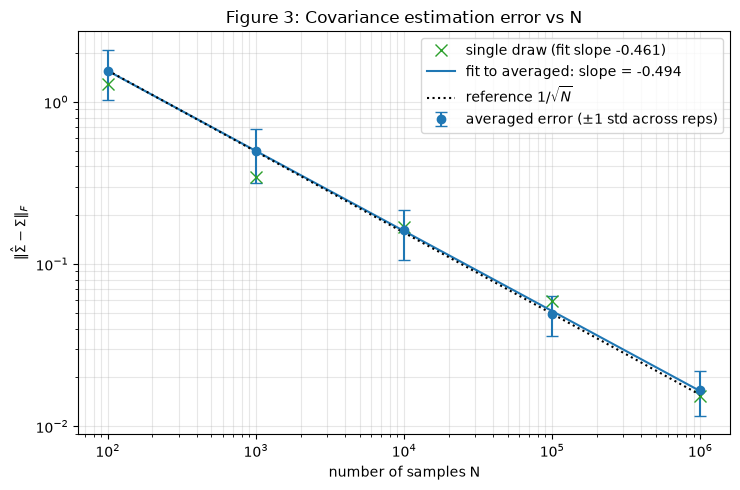

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.errorbar(Ns, avg_err, yerr=std_err, fmt="o", capsize=4, label="averaged error (±1 std across reps)")
ax.plot(Ns, single, "x", color="C2", ms=9, label=f"single draw (fit slope {slope_one:.3f})")
Nfit = np.logspace(2, 6, 50)
ax.plot(Nfit, 10**icpt_avg * Nfit**slope_avg, "C0-", label=f"fit to averaged: slope = {slope_avg:.3f}")
ax.plot(Nfit, avg_err[0] * np.sqrt(Ns[0] / Nfit), "k:", label=r"reference $1/\sqrt{N}$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set(xlabel="number of samples N", ylabel=r"$\|\hat\Sigma - \Sigma\|_F$",
       title="Figure 3: Covariance estimation error vs N")
ax.legend(); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretation of Figure 3.** The averaged error falls on a straight line in log-log axes with slope close to $-0.5$, i.e. the error decays like $1/\sqrt N$ and drops by about $\sqrt{10} \approx 3.16$ per decade of data. The table above shows $\sqrt N \cdot$ error staying near a constant (about 16) for the averaged curve. The single-draw points scatter around the line because each one is a single random number whose spread (the error bars) is a sizeable fraction of its mean, so a slope fitted to only five such points depends heavily on the luck of each draw.

### How much data does a bigger covariance need?
A $d \times d$ covariance matrix has $d(d+1)/2$ free parameters (the diagonal plus one triangle). Each entry is estimated with error $\propto 1/\sqrt N$, so the squared Frobenius error grows roughly in proportion to the number of parameters, $\|\hat\Sigma - \Sigma\|_F^2 \propto \tfrac{d(d+1)/2}{N}$. Keeping the same accuracy therefore needs $N$ to grow in proportion to the parameter count.

In [16]:
p = lambda d: d * (d + 1) // 2
N_ref = 10**4
N_100 = N_ref * p(100) / p(4)
print(f"Free parameters: d = 4 -> {p(4)},  d = 100 -> {p(100)}")
print(f"Relative accuracy at N = 10^4, d = 4: "
      f"{avg_err[Ns == N_ref][0] / np.linalg.norm(Sigma3, 'fro'):.4f}")
print(f"Samples for the same accuracy at d = 100: about {N_ref} x {p(100)}/{p(4)} = {N_100:.2e}")

Free parameters: d = 4 -> 10,  d = 100 -> 5050
Relative accuracy at N = 10^4, d = 4: 0.0185
Samples for the same accuracy at d = 100: about 10000 x 5050/10 = 5.05e+06


### Why this matters for a 100-element radar
An adaptive radar with 100 array elements needs a $100\times 100$ covariance with 5050 parameters, which by the scaling above would take millions of snapshots, but the interference scene only stays stationary for perhaps tens to hundreds of snapshots, so the estimate is noisy and is even singular when $N < 100$. A designer can fix this with **diagonal loading / shrinkage** (adding a small multiple of $I$ to $\hat\Sigma$ to regularize it), or by imposing structure such as a Toeplitz covariance or reducing the dimension with subarrays or beamspace processing.

In [17]:
# run after final cell
print(f"Total runtime: {time.time() - t_start:.1f} s")

Total runtime: 21.1 s
